In [88]:
%load_ext autoreload
%autoreload 2
import os

import cordex as cx
import geopandas as gpd
from cartopy import crs as ccrs
import pandas as pd
import matplotlib.pyplot as plt

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [85]:
wkd = os.getcwd()
wkd

'/home/g/g300047/SCRIPTS/github/factsheet_africa/Notebooks/COUNTRY_MAPS'

open shape files 

#### Download the shape files for the country you want from diva-gis
downloaded from https://diva-gis.org/data.html 

##### License:
*These data were extracted from the GADM database (www.gadm.org), version 2.5, July 2015. They can be used for non-commercial purposes only.  It is
not allowed to redistribute these data, or use them for commercial purposes, without prior consent.*


In [86]:
# local directory, where I stored the files 

home='/home/g/g300047/GITLAB/climate_fact_data/'
# Admin regions
adm_reg_dir='/work/ch0636/g300047/cicles/regions/DIVA-GIS-DOWNLOAD/adm/'
# Burkina Faso + 3 other regions (ISO3 codes); update as needed
adm_regions = ['BFA', 'CIV', 'TGO']  # TGO has only adm0..adm2
levels_per_iso = {'TGO': 3}  # number of levels (range upper bound)

admfiles = [
    os.path.join(adm_reg_dir, f'{iso}_adm{lvl}.shp')
    for iso in adm_regions
    for lvl in range(levels_per_iso.get(iso, 4))  # others: adm0..adm3
]

# Test read one file
#infile =os.path.join(adm_reg_dir, admfiles[2])
#shpfile= gpd.read_file(infile)  # example: Burkina Faso adm0


In [87]:
plotdir='/work/ch0636/g300047/cicles/factsheet_africa/PLOTS/COUNTRY_ADMIT'
if not os.path.exists(plotdir):
    os.makedirs(plotdir)
    

In [90]:
# Read, select columns and merge
adm_selected_merged = []
selected_columns = ['ISO','NAME_0', 'NAME_1', 'NAME_2', 'geometry']
for f in admfiles:
    gdf = gpd.read_file(f)
    # keep only the columns that exist in this file
    cols_present = [c for c in selected_columns if c in gdf.columns]
    gdf_sel = gdf[cols_present].copy()

    # add missing columns so we can concatenate consistently
    for c in selected_columns:
        if c not in gdf_sel.columns:
            gdf_sel[c] = None

    # ensure column order
    gdf_sel = gdf_sel[selected_columns]
    #print(gdf_sel.head(3))
    adm_selected_merged.append(gdf_sel)


# Save to a single shapefile (optional)
output_adm_selected_shp = os.path.join(adm_reg_dir, 'adm_selected_merged_BKF_TGO_CIV.shp')
os.makedirs(os.path.dirname(output_adm_selected_shp), exist_ok=True)
# concatenate the list into a single GeoDataFrame before saving
gpd.GeoDataFrame(pd.concat(adm_selected_merged, ignore_index=True), crs=crs).to_file(output_adm_selected_shp)

# preview the first rows of the concatenated result
pd.concat(adm_selected_merged, ignore_index=True).head(3)

,ISO,NAME_0,NAME_1,NAME_2,geometry
0,BFA,Burkina Faso,None,None,"POLYGON ((-0.45567 15.08082, -0.45128 15.07672..."
1,BFA,Burkina Faso,Boucle du Mouhoun,None,"POLYGON ((-3.20985 13.69655, -3.18562 13.68533..."
2,BFA,Burkina Faso,Cascades,None,"POLYGON ((-5.2595 10.85468, -5.25912 10.85359,..."


In [94]:
shpfile=gpd.read_file(output_adm_selected_shp)
# plot each country (unique NAME_0) and save
for country in shpfile['NAME_0'].dropna().unique():
    sub = shpfile[shpfile['NAME_0'] == country]
    fig, ax = plt.subplots(figsize=(8, 8))
    shpfile.plot(ax=ax, color='lightgrey', edgecolor='black', linewidth=0.3, alpha=0.5)
    sub.plot(ax=ax, color=gerics_orange, edgecolor='black', linewidth=0.8)
    ax.set_axis_off()
    safe_name = country.replace(' ', '_').replace("'", '').replace('’', '')
    outpath = os.path.join(plotdir, f'ADM_{safe_name}.png')
    fig.savefig(outpath, dpi=300, bbox_inches='tight')
    plt.close(fig)
#shpfile.plot(figsize=(8, 8), color='lightgrey', edgecolor='black', linewidth=0.4)

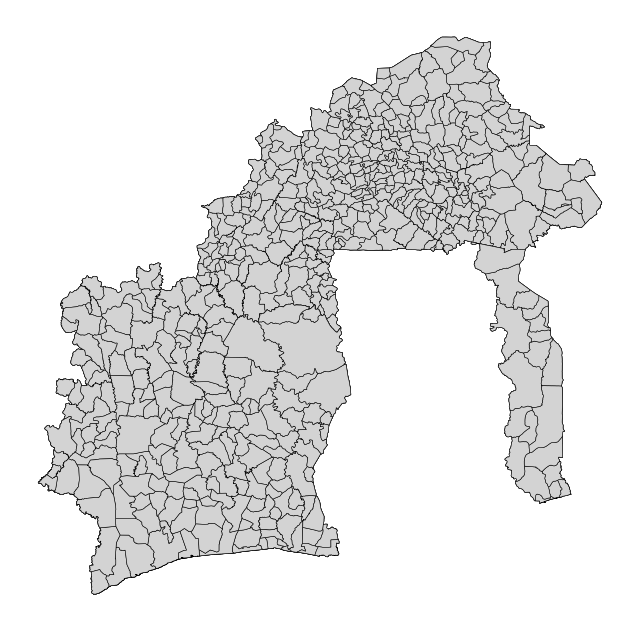

In [92]:
# merge the list of GeoDataFrames and plot
adm_selected_gdf = gpd.GeoDataFrame(
    pd.concat(adm_selected_merged, ignore_index=True),
    crs=crs
)

ax = adm_selected_gdf.plot(figsize=(8, 8), color='lightgrey', edgecolor='black', linewidth=0.4)
ax.set_axis_off()

In [57]:
admfiles[3]

'/work/ch0636/g300047/cicles/regions/DIVA-GIS-DOWNLOAD/adm/BFA_adm3.shp'

look at files

adjust global file to nuts3 file, to make it work in cfd

In [34]:
selected_columns = ['CONTINENT', 'SOV_A3', 'ADM0_DIF', 'LEVEL', 'SOVEREIGNT', 'geometry']

globfile_selected = globfile[selected_columns]

globfile_selected = globfile_selected.rename(columns={
    'SOV_A3': 'ARS',
    'ADM0_DIF': 'ARS_0',
    'LEVEL': 'GEN',
    'SOVEREIGNT': 'region',
    'geometry': 'geometry'
})
#'LABELRANK': 'ADE',
globfile_selected[:3]
#save the selected columns to a new shapefile

output_shpfile = os.path.join(home, 'climate_fact_data/data/shp/globfile_selected.shp')
globfile_selected.to_file(output_shpfile)
globfile_selected[:3]

,CONTINENT,ARS,ARS_0,GEN,region,geometry
0,Asia,IDN,0,2,Indonesia,"MULTIPOLYGON (((117.70361 4.16341, 117.70361 4..."
1,Asia,MYS,0,2,Malaysia,"MULTIPOLYGON (((117.70361 4.16341, 117.69711 4..."
2,South America,CHL,0,2,Chile,"MULTIPOLYGON (((-69.51009 -17.50659, -69.50611..."


select wascal countries

In [35]:
WASCAL_countries = ['Benin', 
    'Burkina Faso', 
    #'Cabo Verde',
    'Ivory Coast', 
    'Gambia',
    'Ghana', 
    'Guinea',
    'Niger',
    'Mali', 
    'Nigeria', 
    'Senegal', 
    'Togo']


In [36]:
# Filter the DataFrame to include only the countries in Africa
globfile_selected_africa = globfile_selected[globfile_selected['CONTINENT'] == 'Africa']
# Save the filtered DataFrame to a new shapefile
output_shpfile = os.path.join(home, 'climate_fact_data/data/shp/globfile_selected_Africa.shp')  
globfile_selected_africa.to_file(output_shpfile)
globfile_selected_africa[:3]
#globfile_selected_africa.plot()

,CONTINENT,ARS,ARS_0,GEN,region,geometry
13,Africa,ETH,0,2,Ethiopia,"POLYGON ((34.0707 9.45459, 34.06689 9.53118, 3..."
14,Africa,SDS,0,2,South Sudan,"POLYGON ((35.92084 4.61933, 35.85654 4.6196, 3..."
15,Africa,SOM,0,2,Somalia,"POLYGON ((46.46696 6.53829, 46.48805 6.55864, ..."


<Axes: >

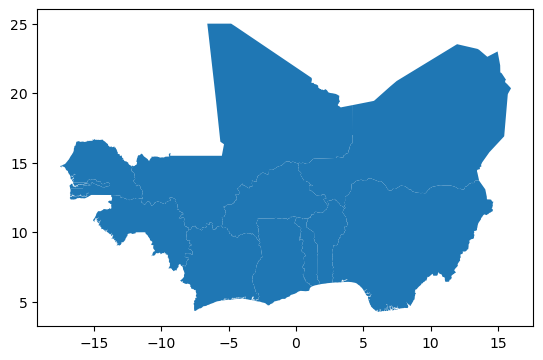

In [37]:
# Filter the DataFrame to include only the countries in WASCAL_countries
globfile_selected_w = globfile_selected[globfile_selected['region'].isin(WASCAL_countries)]
# Save the filtered DataFrame to a new shapefile
output_shpfile = os.path.join(home, 'climate_fact_data/data/shp/globfile_selected_WASCAL.shp')  
globfile_selected_w.to_file(output_shpfile)
globfile_selected_w[:3]
globfile_selected_w.plot()

In [38]:
globfile_w[:3]
globfile_selected_w[:3]


,CONTINENT,ARS,ARS_0,GEN,region,geometry
82,Africa,GIN,0,2,Guinea,"POLYGON ((-13.3011 9.04149, -13.31237 9.04833,..."
95,Africa,CIV,0,2,Ivory Coast,"MULTIPOLYGON (((-7.98966 10.16199, -7.9709 10...."
97,Africa,MLI,0,2,Mali,"POLYGON ((-12.26413 14.77494, -12.24679 14.767..."


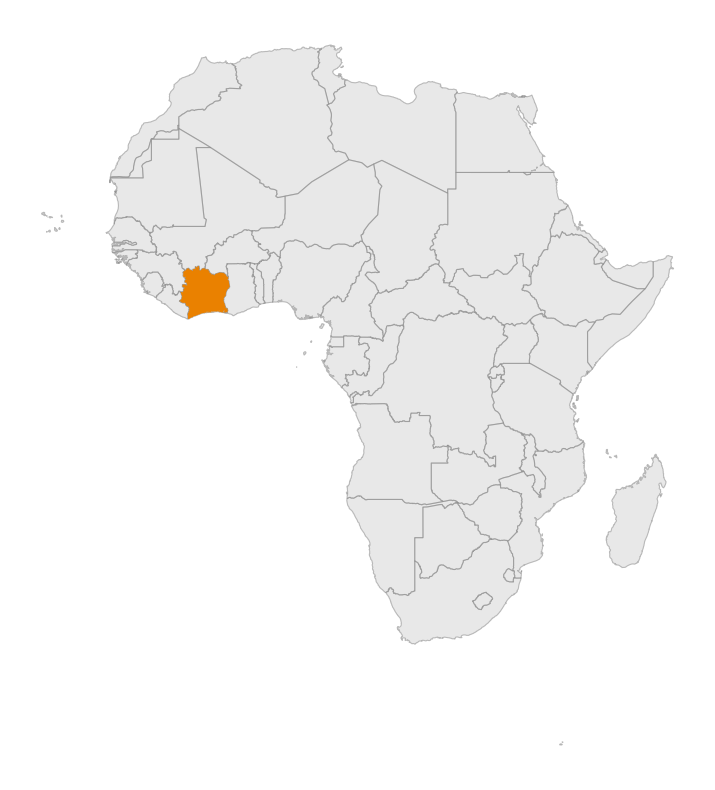

In [39]:
import matplotlib.pyplot as plt
africa = globfile[globfile['CONTINENT'] == 'Africa']


# Plot Africa
fig, ax = plt.subplots(figsize=(10, 10))
africa.plot(ax=ax, color='lightgrey', edgecolor='grey', alpha=0.5, linewidth=0.8)


# Highlight all countries from WASCAL_countries in paired colors
#colors = plt.cm.Paired(range(len(WASCAL_countries)))
#for i, country in enumerate(WASCAL_countries):
#    africa[africa['SOVEREIGNT'] == country].plot(ax=ax, color=colors[i],
#                                                  edgecolor='darkgrey',
#                                                  linewidth=0.8,
#                                                  alpha=0.9)
    #africa.boundary.plot(ax=ax, color='grey')
gerics_orange = (234/255, 129/255, 0)
# Plot only the fact sheet country orange:
#select country: 
#FScountry='Burkina Faso'
#FScountry='Togo'
FScountry='Ivory Coast'
africa[africa['SOVEREIGNT'] == FScountry].plot(ax=ax, color=gerics_orange) #, edgecolor='black')
# Set plot title and remove axis
#ax.set_title('Map of Africa with WASCAL countries highlighted and Cote d\'Ivoire (dark grey)')
#ax.set_title('Map of Burkina Faso ')
ax.axis('off')
# Save the plot to a file
FScountry=str.replace(FScountry, ' ', '_')

output_plot_path = os.path.join(plotdir, 'FS_' + FScountry + '.png')
fig.savefig(output_plot_path, dpi=300, bbox_inches='tight')
# Show plot
plt.show()